
# Notebook 03 — Statistical Model Exploration

### 1. Purpose and Research Question

Notebook 02 established three original forecasting baselines: Zero Naive, Weekly Seasonal Naive, and Recent Mean (7-day).

Recent Mean (7-day) performed best among these original baselines across all three horizons on the 50% sample.

| Forecast Horizon | Recent Mean 7D WAPE |
|---|---:|
| 7 days | 77.52% |
| 14 days | 79.06% |
| 28 days | 81.01% |

However, demand patterns are highly heterogeneous. Sparse, intermittent, and lumpy demand remain difficult to forecast using a short historical average.

**Research Question:** Can statistical forecasting methods improve overall accuracy and sparse-demand performance without introducing unacceptable forecast bias or worsening performance on other demand types?

### 2. Statistical Models

#### Family A — Croston-Based Intermittent Demand Models

- **Croston:** Smooths nonzero demand size and intervals between sales separately.
- **SBA (Syntetos-Boylan Approximation):** Applies a bias correction to Croston's demand-rate estimate.
- **TSB (Teunter-Syntetos-Babai):** Separately estimates demand size and demand occurrence probability, allowing forecasts to respond to declining sales frequency.

#### Family B — Exponential Smoothing

- **SES (Simple Exponential Smoothing / ETS(A,N,N)):** Updates the estimated demand level using exponentially weighted observations.

Unlike Croston-family methods, SES does not explicitly model the interval between sales.

### 3. Baselines and Control

The experiment retains:

- Zero Naive
- Weekly Seasonal Naive
- Recent Mean (7-day) — reference baseline
- Recent Mean (28-day) — longer-window control

The 28-day control tests whether improvements come from specialized statistical modeling or simply from using a longer averaging window.

All baseline models are recomputed within this notebook using the same evaluation engine.

### 4. Evaluation Consistency

The following are held constant across the baseline and statistical experiments:

- Original M5 source files and canonical sample manifests
- 20% and 50% stratified samples
- Training, validation, and test boundaries
- Rolling-origin evaluation with a 7-day step
- Forecast horizons of 7, 14, and 28 days
- Demand-type thresholds: ADI = 1.32 and CV² = 0.49
- Demand-type classification using training data only
- WAPE, RMSE, and signed forecast bias

The 50% sample is used as a larger-sample robustness check, not an independent validation set, because the samples overlap.

### 5. Parameter Tuning and Model Selection

Smoothing parameters are selected on 2015 validation data using candidates of 0.05, 0.10, and 0.20.

- **Croston, SBA, and TSB:** Minimize average Intermittent + Lumpy WAPE across three horizons on the 20% sample.
- **SES:** Minimize average Overall WAPE across three horizons on the 20% sample.

The original four decision checks require candidates to:

1. Reduce Intermittent + Lumpy WAPE by at least 2% relative to Recent Mean 7D.
2. Outperform the Recent Mean 28D control on those demand types.
3. Avoid increasing Smooth + Erratic WAPE by more than 2%.
4. Keep absolute overall forecast bias within the predefined threshold or no worse than the reference baseline.

A candidate must satisfy all four checks on both samples at all three horizons.

The original Croston-family selection protocol remains unchanged. Applying the same checks to SES is an additional exploratory diagnostic.

### 6. Held-Out Evaluation

Only models meeting the original selection requirements qualify for confirmatory testing.

Additional 2016 comparisons of TSB and SES are explicitly exploratory. Their parameters are fixed using 2015 validation and are not retuned on test results.

### 7. Notebook Organization

| # | Section | Purpose |
|---|---|---|
| 1 | Settings and Data Loading | Restore canonical M5 data, samples, time splits, demand types, and experiment settings |
| 2 | Models | Implement baselines, Croston, SBA, TSB, and SES |
| 3 | Evaluation Engine | Calculate rolling-origin WAPE, RMSE, and signed bias |
| 4 | Reproduction Check | Verify original baseline results before statistical comparison |
| 5 | Parameter Tuning | Select smoothing parameters using 2015 validation |
| 6 | Results | Compare model performance across samples, horizons, and demand types |
| 7 | Model Selection | Apply predefined decision checks and document screening outcomes |
| 8 | Held-Out Test | Perform eligible confirmatory tests and labeled exploratory 2016 comparisons |
| 9 | Save Results | Export statistical experiment tables, figures, and experiment metadata |

### 8. Data Dependencies and Outputs

**Inputs:** Original M5 Sales CSV, Calendar CSV, and existing 20%/50% sampling manifests created by the shared preparation workflow.

**Outputs:** Statistical evaluation results and experiment metadata under `statistical_experiment/tables/`, plus figures under `statistical_experiment/figures/`.

These outputs support the downstream LightGBM comparison. This notebook does not replace or overwrite the final LightGBM forecast files used by the RAG workflow.

### Expected Outcome

The objective is not to assume that statistical methods should replace the baselines or LightGBM.

The experiment determines which demand patterns benefit from statistical models, whether improvements justify added complexity, and how accuracy and forecast bias affect inventory decision quality.


## 1. Settings and data loading

In [ ]:

import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
warnings.filterwarnings("ignore", category=RuntimeWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# ---- Paths ----
BASE_PATH = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 EDA/datasets/"
FORECAST_DIR = Path("/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/")
OUT = FORECAST_DIR / "statistical_experiment"
TABLES_OUT = OUT / "tables"
FIGURES_OUT = OUT / "figures"
TABLES_OUT.mkdir(parents=True, exist_ok=True)
FIGURES_OUT.mkdir(parents=True, exist_ok=True)
SALES_FILE = "sales_train_evaluation.csv"

# ---- Evaluation settings ----
HORIZONS = (7, 14, 28)
STEP = 7
ADI_CUT, CV2_CUT = 1.32, 0.49
DEMAND_TYPES = ["Smooth", "Erratic", "Intermittent", "Lumpy", "No sales"]

# ---- Candidate settings ----
ALPHAS = (0.05, 0.10, 0.20)
ETS_ALPHAS = (0.05, 0.10, 0.20)
CONTROL_WINDOW = 28

# ---- Decision rule ----
MIN_REL_GAIN = 0.02
MAX_ABS_BIAS_PP = 1.0

# ---- Held-out test period ----
RUN_CROSTON_TEST = False
RUN_TSB_TEST = True
RUN_ETS_TEST = True
print("Outputs will be saved to:", OUT)


Mounted at /content/drive
Outputs will be saved to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/statistical_experiment


In [ ]:
# Load calendar and sales (memory-efficient types, as in the baseline notebook)
calendar = pd.read_csv(BASE_PATH + "calendar.csv", parse_dates=["date"])
ID_COLS = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
_header = pd.read_csv(BASE_PATH + SALES_FILE, nrows=1).columns
day_cols = sorted([c for c in _header if c.startswith("d_")], key=lambda c: int(c.split("_")[1]))
sales = pd.read_csv(BASE_PATH + SALES_FILE,
                    dtype={**{c: "category" for c in ID_COLS[1:]}, **{c: "int16" for c in day_cols}})

# Chronological splits (same dates as the baseline notebook)
dates = pd.DatetimeIndex(calendar.set_index("d").loc[day_cols, "date"])
assert dates.is_monotonic_increasing and dates.is_unique
TRAIN_LEN = int((dates <= pd.Timestamp("2014-12-31")).sum())     # train: 2011-01-29 to 2014-12-31
VAL_END   = int((dates <= pd.Timestamp("2015-12-31")).sum())     # validation: all of 2015
N_DAYS    = len(day_cols)                                        # test: 2016-01-01 onward
assert (TRAIN_LEN, VAL_END - TRAIN_LEN, N_DAYS - VAL_END) == (1433, 365, 143), "Split lengths differ from the baseline notebook"
print(f"Train {TRAIN_LEN} days | Validation {VAL_END - TRAIN_LEN} days | Test {N_DAYS - VAL_END} days")

Train 1433 days | Validation 365 days | Test 143 days


In [ ]:
# Load the same 20% and 50% samples the baseline notebook exported (so we compare on identical series)
def load_ids(name):
    path = FORECAST_DIR / f"sample_{name}_manifest.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Re-run the baseline notebook's sampling export first.")
    return pd.read_csv(path)["id"]

ids20, ids50 = load_ids("20"), load_ids("50")
assert len(ids20) == 6098 and len(ids50) == 15245 and set(ids20) <= set(ids50)

def build_sample(ids):
    sel = sales.loc[sales["id"].isin(set(ids)), ID_COLS + day_cols]
    assert len(sel) == len(ids)
    meta = sel[ID_COLS].copy().reset_index(drop=True)
    for c in ID_COLS[1:]:
        meta[c] = meta[c].astype(str)
    matrix = sel[day_cols].to_numpy(dtype=np.float32)          # all days; validation never looks past VAL_END
    assert np.isfinite(matrix).all() and (matrix >= 0).all()
    return meta, matrix

meta20, M20 = build_sample(ids20)
meta50, M50 = build_sample(ids50)
print("20% sample:", M20.shape, "| 50% sample:", M50.shape)

# Demand types: exactly the baseline notebook's rule, from TRAINING data only
def classify_demand_types(train_matrix, metadata):
    x = np.asarray(train_matrix, dtype=np.float64)
    n_series, n_days = x.shape
    positive = x > 0
    n_sales_days = positive.sum(axis=1)
    has_sales = n_sales_days > 0
    first_sale = np.where(has_sales, positive.argmax(axis=1), n_days)
    adi = np.full(n_series, np.nan)
    adi[has_sales] = (n_days - first_sale[has_sales]) / n_sales_days[has_sales]
    mean = np.divide(x.sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales)
    var = np.maximum(np.divide((x ** 2).sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales) - mean ** 2, 0)
    cv2 = np.divide(var, mean ** 2, out=np.full(n_series, np.nan), where=mean > 0)
    demand_type = np.select([~has_sales, (adi < ADI_CUT) & (cv2 < CV2_CUT), (adi < ADI_CUT) & (cv2 >= CV2_CUT), (adi >= ADI_CUT) & (cv2 < CV2_CUT)],
                            ["No sales", "Smooth", "Erratic", "Intermittent"], default="Lumpy")
    result = metadata.copy().reset_index(drop=True)
    result["ADI"], result["CV2"], result["Demand_Type"] = adi, cv2, demand_type
    return result

meta20 = classify_demand_types(M20[:, :TRAIN_LEN], meta20)
meta50 = classify_demand_types(M50[:, :TRAIN_LEN], meta50)
for label, m in [("20%", meta20), ("50%", meta50)]:
    print(f"\n{label} sample, series share by demand type (%)")
    display(m["Demand_Type"].value_counts(normalize=True).mul(100).round(2).to_frame("share"))

def make_segments(meta):
    seg = {"All": np.ones(len(meta), dtype=bool)}
    for t in DEMAND_TYPES:
        seg[t] = (meta["Demand_Type"] == t).to_numpy()
    seg["Intermittent+Lumpy"] = seg["Intermittent"] | seg["Lumpy"]
    seg["Smooth+Erratic"] = seg["Smooth"] | seg["Erratic"]
    for c in sorted(meta["cat_id"].unique()):
        seg[f"cat:{c}"] = (meta["cat_id"] == c).to_numpy()
    return seg

SEG20, SEG50 = make_segments(meta20), make_segments(meta50)

20% sample: (6098, 1941) | 50% sample: (15245, 1941)

20% sample, series share by demand type (%)


,share
Demand_Type,
Intermittent,70.25
Lumpy,16.83
Smooth,6.81
No sales,3.23
Erratic,2.89



50% sample, series share by demand type (%)


,share
Demand_Type,
Intermittent,70.32
Lumpy,16.96
Smooth,6.70
No sales,3.23
Erratic,2.79



## 2. Models

**Simple Baselines:** Zero Naive, Weekly Seasonal Naive, Recent Mean (7-day), and Recent Mean (28-day). They are recomputed here so every model is scored by the same evaluation code, and we first verify that the results match the baseline notebook's published numbers.

**Croston Family (Intermittent Demand):** Croston, SBA, and TSB. These methods model sparse demand through nonzero demand sizes, sales intervals, or demand occurrence probabilities. Each is tested at several smoothing levels (`ALPHAS`).

**ETS Family (Exponential Smoothing):** Simple Exponential Smoothing (SES / ETS(A,N,N)). SES recursively updates the demand level using exponentially weighted historical sales. It is tested using `ETS_ALPHAS`.

Each model produces forecasts at the same rolling origins, using only sales data available up to that origin, and is evaluated over identical horizons.

*Reading the results.* WAPE rewards forecasts close to the median of sparse demand, which is often zero. Croston-family methods instead estimate average demand rates. RMSE and signed bias are reported alongside WAPE, with results segmented by demand type.


In [ ]:
def origins_for(horizon, first_origin, end_idx, step=STEP):
    """Same rule as the baseline notebook: a full horizon must fit before end_idx."""
    out, o = [], first_origin
    while o + horizon < end_idx:
        out.append(o)
        o += step
    return out

def recent_mean_forecasts(M, window, origins):
    cs = np.cumsum(M, axis=1, dtype=np.float64)
    out = {o: ((cs[:, o] - cs[:, o - window]) / window).astype(np.float32) for o in origins}
    del cs
    return out

def croston_family(M, origins, alpha, kind):
    """kind: 'croston' | 'sba' | 'tsb'. One forecast per series at each origin, using only days <= origin.
    State is updated one day at a time for all series at once."""
    n = M.shape[0]
    need, last = set(origins), max(origins)
    z = np.zeros(n); q = np.ones(n); k = np.zeros(n); p = np.zeros(n)
    started = np.zeros(n, dtype=bool)
    out = {}
    for t in range(last + 1):
        y = M[:, t].astype(np.float64)
        occ = y > 0
        first = occ & ~started
        cont = occ & started
        z = np.where(first, y, np.where(cont, z + alpha * (y - z), z))
        if kind == "tsb":
            p = np.where(started, p + alpha * (occ.astype(np.float64) - p), p)   # probability of a sale
            p = np.where(first, 1.0, p)
        else:
            k = np.where(started, k + 1, k)                                       # days since last sale
            q = np.where(first, 1.0, np.where(cont, q + alpha * (k - q), q))      # smoothed gap between sales
            k = np.where(occ, 0.0, k)
        started = started | first
        if t in need:
            if kind == "tsb":
                f = p * z
            else:
                f = np.where(started, z / q, 0.0)
                if kind == "sba":
                    f = f * (1 - alpha / 2)
            out[t] = f.astype(np.float32)
    return out

def build_models(M, first_origin, end_idx, alphas=ALPHAS, kinds=("croston", "sba", "tsb"), include_baselines=True):
    origins = origins_for(min(HORIZONS), first_origin, end_idx)
    models = {}
    if include_baselines:
        models["zero_naive"] = {"kind": "zero"}
        models["weekly_seasonal_naive"] = {"kind": "snaive"}
        models["recent_mean_7"] = {"kind": "flat", "flat": recent_mean_forecasts(M, 7, origins)}
    models[f"recent_mean_{CONTROL_WINDOW}"] = {"kind": "flat", "flat": recent_mean_forecasts(M, CONTROL_WINDOW, origins)}
    for kind in kinds:
        for a in alphas:
            models[f"{kind}_a{a:g}"] = {"kind": "flat", "flat": croston_family(M, origins, a, kind)}
    return models

def forecast_block(spec, M, o, h):
    n = M.shape[0]
    if spec["kind"] == "zero":
        return np.zeros((n, h))
    if spec["kind"] == "snaive":
        return np.tile(M[:, o - 6:o + 1], (1, int(np.ceil(h / 7))))[:, :h].astype(np.float64)
    return np.repeat(spec["flat"][o][:, None].astype(np.float64), h, axis=1)

def ses_forecasts(M, origins, alpha):
    """Simple Exponential Smoothing: one flat forecast per series at each origin."""
    if not 0 < alpha <= 1: raise ValueError("alpha must be in (0, 1].")
    origins = sorted(set(origins))
    if not origins: return {}
    level = M[:, 0].astype(np.float64).copy()
    out, need = {}, set(origins)
    if 0 in need: out[0] = level.astype(np.float32).copy()
    for t in range(1, max(origins) + 1):
        level += alpha * (M[:, t] - level)
        if t in need: out[t] = level.astype(np.float32).copy()
    return out


## 3. Evaluation engine

Expanding-window rolling-origin evaluation, identical in method to the baseline notebook: the first origin is the last training day, the origin moves forward 7 days at a time, and every forecast is scored against the next 7, 14, or 28 actual days. Errors are accumulated per series and then **pooled** (sum of errors divided by sum of sales), overall and for each segment, so grouped results add back up to the overall result.

- **WAPE** = total absolute error ÷ total actual sales × 100
- **Bias** = total signed error ÷ total actual sales × 100 (negative = under-forecast)
- **MAE / RMSE** = pooled, per series-day

In [ ]:
def evaluate(M, models, segments, first_origin, end_idx, horizons=HORIZONS):
    n = M.shape[0]
    acc = {(m, h): [np.zeros(n), np.zeros(n), np.zeros(n)] for m in models for h in horizons}
    act = {h: np.zeros(n) for h in horizons}
    n_orig = {h: 0 for h in horizons}
    for h in horizons:
        for o in origins_for(h, first_origin, end_idx):
            assert o + 1 + h <= end_idx                      # never looks past end_idx (validation: VAL_END)
            actual = M[:, o + 1:o + 1 + h].astype(np.float64)
            act[h] += actual.sum(axis=1)
            n_orig[h] += 1
            for m, spec in models.items():
                e = forecast_block(spec, M, o, h) - actual
                a = acc[(m, h)]
                a[0] += np.abs(e).sum(axis=1)
                a[1] += (e * e).sum(axis=1)
                a[2] += e.sum(axis=1)
    rows = []
    for (m, h), (sa, ss, sg) in acc.items():
        for sname, mask in segments.items():
            tot = act[h][mask].sum()
            nobs = int(mask.sum()) * h * n_orig[h]
            rows.append({"model": m, "horizon": h, "segment": sname, "n_series": int(mask.sum()), "n_origins": n_orig[h],
                         "MAE": sa[mask].sum() / nobs if nobs else np.nan,
                         "RMSE": np.sqrt(ss[mask].sum() / nobs) if nobs else np.nan,
                         "WAPE_pct": 100 * sa[mask].sum() / tot if tot > 0 else np.nan,
                         "Bias_pct": 100 * sg[mask].sum() / tot if tot > 0 else np.nan})
    return pd.DataFrame(rows)

FIRST_VAL_ORIGIN = TRAIN_LEN - 1       # last training day, as in the baseline notebook

## 4. Reproduction check

Before trusting any new result, recompute the baselines here and compare them with the numbers published in the baseline notebook. They should match to within about 0.01 percentage points. If they do not, the sample files or the data version differ and the comparison would not be fair, so stop and tell me.

In [ ]:
import time
t0 = time.time()
print("Building forecasts and evaluating on the validation period (this takes a few minutes)...")
models20 = build_models(M20, FIRST_VAL_ORIGIN, VAL_END)
res20 = evaluate(M20, models20, SEG20, FIRST_VAL_ORIGIN, VAL_END); res20["sample"] = "20%"
print(f"20% done ({time.time() - t0:.0f}s)")
models50 = build_models(M50, FIRST_VAL_ORIGIN, VAL_END)
res50 = evaluate(M50, models50, SEG50, FIRST_VAL_ORIGIN, VAL_END); res50["sample"] = "50%"
print(f"50% done ({time.time() - t0:.0f}s)")
val_results = pd.concat([res20, res50], ignore_index=True)

Building forecasts and evaluating on the validation period (this takes a few minutes)...
20% done (7s)
50% done (23s)


In [ ]:
# WAPE figures published in the baseline notebook (overall, by horizon)
PUBLISHED = {
    ("20%", "recent_mean_7"):        {7: 76.4770, 14: 78.0601, 28: 80.0777},
    ("20%", "weekly_seasonal_naive"):{7: 89.9398, 14: 91.3447, 28: 93.0013},
    ("20%", "zero_naive"):           {7: 100.0,   14: 100.0,   28: 100.0},
    ("50%", "recent_mean_7"):        {7: 77.5216, 14: 79.0587, 28: 81.0121},
    ("50%", "weekly_seasonal_naive"):{7: 91.1185, 14: 92.4116, 28: 94.0158},
    ("50%", "zero_naive"):           {7: 100.0,   14: 100.0,   28: 100.0},
}
chk = []
for (smp, model), by_h in PUBLISHED.items():
    for h, pub in by_h.items():
        mine = val_results.query("sample == @smp and model == @model and horizon == @h and segment == 'All'")["WAPE_pct"].iloc[0]
        chk.append({"sample": smp, "model": model, "horizon": h, "published_WAPE": pub, "this_notebook": round(mine, 4), "abs_diff": round(abs(mine - pub), 4)})
chk = pd.DataFrame(chk)
display(chk)
REPRO_OK = bool((chk["abs_diff"] < 0.01).all())
print("REPRODUCTION CHECK:", "PASSED" if REPRO_OK else "FAILED: results differ from the baseline notebook, do not interpret what follows")
assert REPRO_OK, (
    "Baseline reproduction failed. "
    "Check sample manifests, chronological splits, "
    "and evaluation logic before continuing."
)


,sample,model,horizon,published_WAPE,this_notebook,abs_diff
0,20%,recent_mean_7,7,76.4770,76.4770,0.0
1,20%,recent_mean_7,14,78.0601,78.0601,0.0
2,20%,recent_mean_7,28,80.0777,80.0777,0.0
3,20%,weekly_seasonal_naive,7,89.9398,89.9398,0.0
4,20%,weekly_seasonal_naive,14,91.3447,91.3447,0.0
5,20%,weekly_seasonal_naive,28,93.0013,93.0013,0.0
6,20%,zero_naive,7,100.0000,100.0000,0.0
7,20%,zero_naive,14,100.0000,100.0000,0.0
8,20%,zero_naive,28,100.0000,100.0000,0.0
9,50%,recent_mean_7,7,77.5216,77.5216,0.0


REPRODUCTION CHECK: PASSED


## 5. Choose a smoothing level for each model family

### 5A. Croston Family — Intermittent-Demand Tuning

Each Croston-family method was run at several smoothing levels. For each method, we keep the level with the lowest WAPE on **Intermittent + Lumpy series in the 20% sample**, averaged over the three horizons. This preserves the original tuning approach.

### 5B. ETS Family — Overall Demand Tuning

SES is tested at the same smoothing levels (0.05, 0.10, 0.20). Its parameter is selected using the lowest **Overall WAPE in the 20% sample**, averaged over the three horizons.

Both families are tuned using 2015 validation data only.

*Caveat:* The 20% sample is part of the 50% sample, so the 50% results provide a consistency check rather than an independent test. The held-out 2016 test period is reserved for separate evaluation.


In [ ]:

# Croston family: tune on Intermittent + Lumpy WAPE
il20 = res20.query("segment == 'Intermittent+Lumpy'").copy()
il20["model_type"] = il20["model"].str.extract(r"^(croston|sba|tsb)_a")[0]
tune = (il20.dropna(subset=["model_type"]).groupby(["model_type", "model"])["WAPE_pct"].mean().rename("mean_WAPE_IntLumpy_20pct").reset_index())
display(tune.round(3))
TUNED = tune.loc[tune.groupby("model_type")["mean_WAPE_IntLumpy_20pct"].idxmin(), "model"].tolist()
print("Croston family selected:", TUNED)

# ETS family: tune on Overall WAPE
def evaluate_ses(M, segments, sample):
    origins = origins_for(min(HORIZONS), FIRST_VAL_ORIGIN, VAL_END)
    models = {f"ses_a{a:g}": {"kind": "flat", "flat": ses_forecasts(M, origins, a)} for a in ETS_ALPHAS}
    result = evaluate(M, models, segments, FIRST_VAL_ORIGIN, VAL_END)
    result["sample"] = sample
    return result

ets20 = evaluate_ses(M20, SEG20, "20%")
ets50 = evaluate_ses(M50, SEG50, "50%")
ets_results = pd.concat([ets20, ets50], ignore_index=True)
ets_tuning = (ets20.query("segment == 'All'").groupby("model", as_index=False)["WAPE_pct"].mean().rename(columns={"WAPE_pct": "mean_WAPE_Overall_20pct"}).sort_values(["mean_WAPE_Overall_20pct", "model"]))
BEST_ETS = ets_tuning.iloc[0]["model"]
print("\nETS family tuning:"); display(ets_tuning.round(3))
print("ETS family selected:", BEST_ETS)

# Combined validation results
val_results = pd.concat([res20, res50, ets_results], ignore_index=True)

def model_family(model):
    if model.startswith(("croston_", "sba_", "tsb_")): return "Croston Family"
    if model.startswith("ses_"): return "ETS Family"
    return "Simple Baseline"

def model_type(model):
    if model.startswith("croston_"): return "Croston"
    if model.startswith("sba_"): return "SBA"
    if model.startswith("tsb_"): return "TSB"
    if model.startswith("ses_"): return "SES"
    if model.startswith("recent_mean_"): return "Recent Mean"
    if model == "zero_naive": return "Zero Naive"
    if model == "weekly_seasonal_naive": return "Weekly Seasonal Naive"
    return model

val_results["model_family"] = val_results["model"].map(model_family)
val_results["model_type"] = val_results["model"].map(model_type)
ets_results["model_family"] = ets_results["model"].map(model_family)
ets_results["model_type"] = ets_results["model"].map(model_type)

REF, CTRL = "recent_mean_7", f"recent_mean_{CONTROL_WINDOW}"
SHOW = [REF, CTRL] + TUNED + [BEST_ETS]
ALL_MODELS = ["zero_naive", "weekly_seasonal_naive"] + SHOW
assert not val_results.duplicated(["sample", "model", "horizon", "segment"]).any()

print("\n=== Selected model configurations ===")
selected = val_results[val_results["model"].isin(ALL_MODELS)][["model_family", "model_type", "model"]].drop_duplicates()
display(selected.sort_values(["model_family", "model_type", "model"]).reset_index(drop=True))


,model_type,model,mean_WAPE_IntLumpy_20pct
0,croston,croston_a0.05,102.389
1,croston,croston_a0.1,103.115
2,croston,croston_a0.2,104.778
3,sba,sba_a0.05,101.598
4,sba,sba_a0.1,101.412
5,sba,sba_a0.2,101.146
6,tsb,tsb_a0.05,92.288
7,tsb,tsb_a0.1,91.483
8,tsb,tsb_a0.2,91.627


Croston family selected: ['croston_a0.05', 'sba_a0.2', 'tsb_a0.1']

ETS family tuning:


,model,mean_WAPE_Overall_20pct
1,ses_a0.1,76.795
2,ses_a0.2,76.995
0,ses_a0.05,77.523


ETS family selected: ses_a0.1

=== Selected model configurations ===


,model_family,model_type,model
0,Croston Family,Croston,croston_a0.05
1,Croston Family,SBA,sba_a0.2
2,Croston Family,TSB,tsb_a0.1
3,ETS Family,SES,ses_a0.1
4,Simple Baseline,Recent Mean,recent_mean_28
5,Simple Baseline,Recent Mean,recent_mean_7
6,Simple Baseline,Weekly Seasonal Naive,weekly_seasonal_naive
7,Simple Baseline,Zero Naive,zero_naive


## 6. Results

The selected Croston-family and ETS-family methods are compared with Recent Mean baselines using the same 2015 rolling-origin evaluation framework.

Results are grouped into three model groups: Simple Baselines, Croston Family, and ETS Family.

We compare overall WAPE, RMSE, and signed bias across the three forecast horizons, followed by performance by demand type.

Negative signed bias indicates under-forecasting. Lower WAPE does not necessarily imply lower bias or better inventory decisions.

In [ ]:

# Overall WAPE, bias and RMSE by model family and horizon
for smp in ["20%", "50%"]:
    sub = val_results.query("sample == @smp and segment == 'All' and model in @ALL_MODELS").copy()
    order = pd.MultiIndex.from_tuples([(model_family(m), m) for m in ALL_MODELS], names=["Model Family", "Model"])
    for metric, title in [("WAPE_pct", "WAPE (%)"), ("Bias_pct", "Bias (%)"), ("RMSE", "RMSE")]:
        print(f"\n=== {smp} sample: overall {title} by horizon ===")
        table = sub.pivot(index=["model_family", "model"], columns="horizon", values=metric)
        display(table.reindex(order).round(3 if metric == "RMSE" else 2))



=== 20% sample: overall WAPE (%) by horizon ===


horizon                                    7       14      28
Model Family    Model                                        
Simple Baseline zero_naive             100.00  100.00  100.00
                weekly_seasonal_naive   89.94   91.34   93.00
                recent_mean_7           76.48   78.06   80.08
                recent_mean_28          76.82   77.71   79.32
Croston Family  croston_a0.05           86.42   86.55   86.90
                sba_a0.2                84.88   85.34   85.86
                tsb_a0.1                75.42   76.58   78.33
ETS Family      ses_a0.1                75.42   76.60   78.36


=== 20% sample: overall Bias (%) by horizon ===


horizon                                    7       14      28
Model Family    Model                                        
Simple Baseline zero_naive            -100.00 -100.00 -100.00
                weekly_seasonal_naive   -0.13   -0.48   -0.86
                recent_mean_7           -0.13   -0.48   -0.86
                recent_mean_28          -0.49   -0.77   -0.97
Croston Family  croston_a0.05            7.29    6.90    6.55
                sba_a0.2                 0.77    0.37   -0.02
                tsb_a0.1                -0.98   -1.32   -1.57
ETS Family      ses_a0.1                -1.13   -1.48   -1.74


=== 20% sample: overall RMSE by horizon ===


horizon                                   7      14     28
Model Family    Model                                     
Simple Baseline zero_naive             3.864  3.869  3.871
                weekly_seasonal_naive  2.883  2.948  3.016
                recent_mean_7          2.321  2.394  2.486
                recent_mean_28         2.325  2.369  2.434
Croston Family  croston_a0.05          2.494  2.505  2.518
                sba_a0.2               2.504  2.530  2.554
                tsb_a0.1               2.266  2.321  2.397
ETS Family      ses_a0.1               2.266  2.323  2.400

... (2 outputs left out)


=== 50% sample: overall Bias (%) by horizon ===


horizon                                    7       14      28
Model Family    Model                                        
Simple Baseline zero_naive            -100.00 -100.00 -100.00
                weekly_seasonal_naive   -0.11   -0.46   -0.83
                recent_mean_7           -0.11   -0.46   -0.83
                recent_mean_28          -0.45   -0.73   -0.92
Croston Family  croston_a0.05            7.14    6.74    6.35
                sba_a0.2                 0.87    0.46    0.05
                tsb_a0.1                -0.97   -1.31   -1.56
ETS Family      ses_a0.1                -1.10   -1.44   -1.71


=== 50% sample: overall RMSE by horizon ===


horizon                                   7      14     28
Model Family    Model                                     
Simple Baseline zero_naive             3.672  3.677  3.682
                weekly_seasonal_naive  2.753  2.816  2.882
                recent_mean_7          2.223  2.295  2.381
                recent_mean_28         2.222  2.265  2.326
Croston Family  croston_a0.05          2.371  2.382  2.395
                sba_a0.2               2.379  2.405  2.428
                tsb_a0.1               2.165  2.220  2.291
ETS Family      ses_a0.1               2.166  2.222  2.295

In [ ]:

# Performance by demand type
SEGS = DEMAND_TYPES + ["Intermittent+Lumpy", "Smooth+Erratic"]
FAMILY_COLS = pd.MultiIndex.from_tuples([(model_family(m), m) for m in SHOW], names=["Model Family", "Model"])

for smp in ["20%", "50%"]:
    for h in HORIZONS:
        sub = val_results.query("sample == @smp and horizon == @h and model in @SHOW and segment in @SEGS")
        print(f"\n=== {smp} sample, {h}-day horizon: WAPE (%) by demand type ===")
        table = sub.pivot(index="segment", columns=["model_family", "model"], values="WAPE_pct")
        display(table.reindex(index=SEGS, columns=FAMILY_COLS).round(2))

sub = val_results.query("sample == '50%' and horizon == 7 and model in @SHOW and segment in @SEGS")
for metric, title in [("Bias_pct", "bias (%)"), ("RMSE", "RMSE")]:
    print(f"\n=== 50% sample, 7-day: {title} by demand type ===")
    table = sub.pivot(index="segment", columns=["model_family", "model"], values=metric)
    display(table.reindex(index=SEGS, columns=FAMILY_COLS).round(3 if metric == "RMSE" else 2))



=== 20% sample, 7-day horizon: WAPE (%) by demand type ===


Model Family       Simple Baseline                Croston Family           \
Model                recent_mean_7 recent_mean_28  croston_a0.05 sba_a0.2   
segment                                                                     
Smooth                       48.83          49.64          56.58    55.25   
Erratic                      60.21          61.75          69.88    68.15   
Intermittent                 94.63          94.83         106.99   105.46   
Lumpy                        86.85          86.29          94.90    93.63   
No sales                     87.89          87.79         105.82    98.79   
Intermittent+Lumpy           91.69          91.61         102.43   100.99   
Smooth+Erratic               52.36          53.40          60.71    59.25   

Model Family                ETS Family  
Model              tsb_a0.1   ses_a0.1  
segment                                 
Smooth                48.27      48.22  
Erratic               59.50      59.42  
Intermittent          93.48      93.61  
Lumpy                 85.02      85.11  
No sales              88.64      86.50  
Intermittent+Lumpy    90.29      90.40  
Smooth+Erratic        51.76      51.70


=== 20% sample, 14-day horizon: WAPE (%) by demand type ===


Model Family       Simple Baseline                Croston Family           \
Model                recent_mean_7 recent_mean_28  croston_a0.05 sba_a0.2   
segment                                                                     
Smooth                       50.38          50.46          56.92    56.01   
Erratic                      62.70          63.26          70.50    69.37   
Intermittent                 95.84          95.56         106.87   105.48   
Lumpy                        88.54          87.11          94.89    93.99   
No sales                     89.54          88.67         105.97    99.24   
Intermittent+Lumpy           93.08          92.37         102.34   101.14   
Smooth+Erratic               54.21          54.44          61.14    60.16   

Model Family                ETS Family  
Model              tsb_a0.1   ses_a0.1  
segment                                 
Smooth                49.38      49.36  
Erratic               61.38      61.35  
Intermittent          94.40      94.53  
Lumpy                 86.19      86.30  
No sales              89.83      87.73  
Intermittent+Lumpy    91.30      91.42  
Smooth+Erratic        53.11      53.09


=== 20% sample, 28-day horizon: WAPE (%) by demand type ===


Model Family       Simple Baseline                Croston Family           \
Model                recent_mean_7 recent_mean_28  croston_a0.05 sba_a0.2   
segment                                                                     
Smooth                       52.39          51.98          57.54    56.89   
Erratic                      65.84          65.89          71.52    70.76   
Intermittent                 97.58          96.85         106.87   105.61   
Lumpy                        90.35          88.72          95.01    94.19   
No sales                     91.32          90.57         106.49    99.76   
Intermittent+Lumpy           94.86          93.79         102.40   101.30   
Smooth+Erratic               56.58          56.31          61.89    61.21   

Model Family                ETS Family  
Model              tsb_a0.1   ses_a0.1  
segment                                 
Smooth                51.05      51.06  
Erratic               64.15      64.20  
Intermittent          95.90      96.01  
Lumpy                 87.82      87.91  
No sales              91.49      89.59  
Intermittent+Lumpy    92.85      92.95  
Smooth+Erratic        55.13      55.15

... (6 outputs left out)


=== 50% sample, 7-day: bias (%) by demand type ===


Model Family       Simple Baseline                Croston Family           \
Model                recent_mean_7 recent_mean_28  croston_a0.05 sba_a0.2   
segment                                                                     
Smooth                        0.15           0.38           5.63    -5.07   
Erratic                      -0.20          -0.51           5.61    -2.65   
Intermittent                 -0.16          -0.63           8.63     5.12   
Lumpy                        -0.13          -0.64           6.06     2.04   
No sales                     -2.40          -6.70          23.40     7.89   
Intermittent+Lumpy           -0.15          -0.64           7.69     3.99   
Smooth+Erratic                0.04           0.11           5.62    -4.34   

Model Family                ETS Family  
Model              tsb_a0.1   ses_a0.1  
segment                                 
Smooth                -0.59      -0.62  
Erratic               -1.38      -1.29  
Intermittent          -1.16      -1.20  
Lumpy                 -1.05      -1.09  
No sales               0.93      -5.79  
Intermittent+Lumpy    -1.12      -1.16  
Smooth+Erratic        -0.83      -0.82


=== 50% sample, 7-day: RMSE by demand type ===


Model Family       Simple Baseline                Croston Family           \
Model                recent_mean_7 recent_mean_28  croston_a0.05 sba_a0.2   
segment                                                                     
Smooth                       4.202          4.198          4.433    4.482   
Erratic                      5.441          5.445          5.839    5.873   
Intermittent                 1.292          1.335          1.495    1.476   
Lumpy                        3.178          3.103          3.193    3.231   
No sales                     1.172          1.161          1.278    1.238   
Intermittent+Lumpy           1.818          1.818          1.945    1.945   
Smooth+Erratic               4.602          4.601          4.889    4.932   

Model Family                ETS Family  
Model              tsb_a0.1   ses_a0.1  
segment                                 
Smooth                4.094      4.090  
Erratic               5.290      5.286  
Intermittent          1.276      1.277  
Lumpy                 3.067      3.073  
No sales              1.149      1.143  
Intermittent+Lumpy    1.772      1.774  
Smooth+Erratic        4.480      4.476

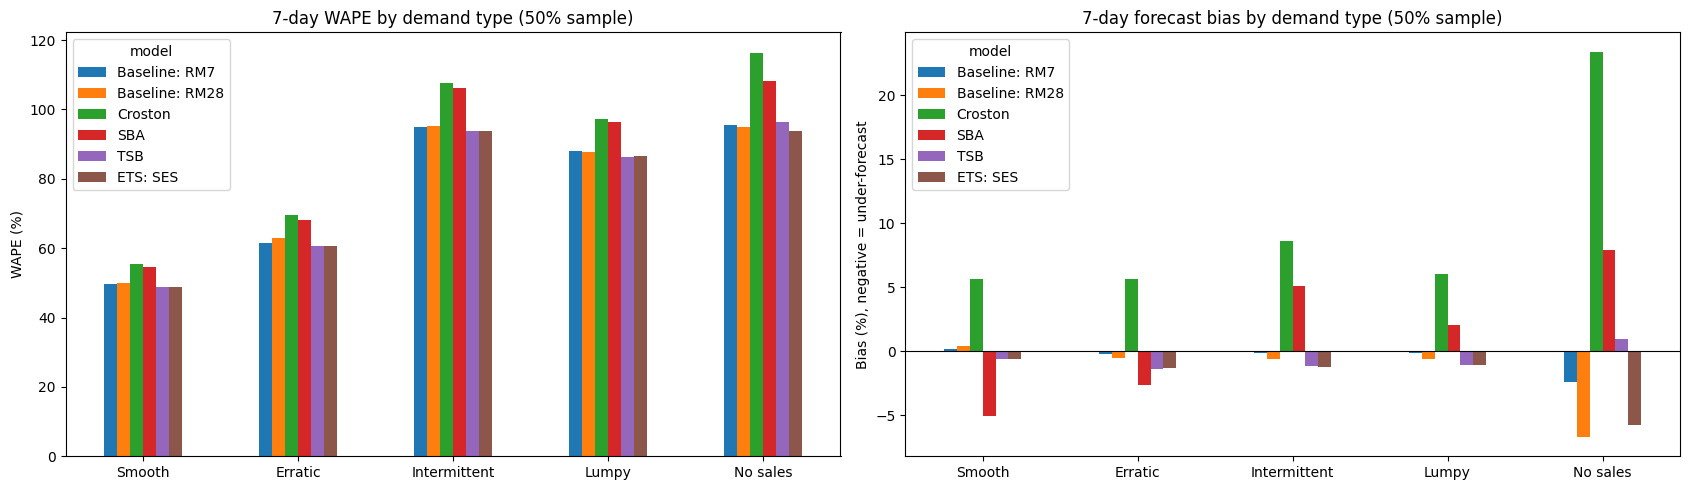

In [ ]:

# Charts: 7-day WAPE and bias by demand type, 50% sample
sub = val_results.query("sample == '50%' and horizon == 7 and model in @SHOW and segment in @DEMAND_TYPES")
LABELS = {"recent_mean_7": "Baseline: RM7", "recent_mean_28": "Baseline: RM28",
          "croston_a0.05": "Croston", "sba_a0.2": "SBA", "tsb_a0.1": "TSB", BEST_ETS: "ETS: SES"}
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sub.pivot(index="segment", columns="model", values="WAPE_pct").loc[DEMAND_TYPES, SHOW].rename(columns=LABELS).plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("7-day WAPE by demand type (50% sample)"); axes[0].set_ylabel("WAPE (%)"); axes[0].set_xlabel("")
sub.pivot(index="segment", columns="model", values="Bias_pct").loc[DEMAND_TYPES, SHOW].rename(columns=LABELS).plot(kind="bar", ax=axes[1], rot=0)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("7-day forecast bias by demand type (50% sample)"); axes[1].set_ylabel("Bias (%), negative = under-forecast"); axes[1].set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURES_OUT / "stat_wape_bias_by_demand_type_50_7d.png", dpi=200, bbox_inches="tight"); plt.show()



## 7. Model selection and diagnostic screening

The four selection rules are applied across both samples (20% and 50%) and all three forecast horizons (7, 14, and 28 days). A candidate must pass every check in all six sample-horizon combinations.

**Croston Family — Original Selection:** Croston, SBA, and TSB are evaluated using the original selection criteria. Only candidates passing all four checks qualify for confirmatory held-out testing.

**ETS Family — Exploratory Diagnostic:** SES is evaluated against the same criteria for comparison. Since the rules were originally designed for intermittent-demand forecasting, the SES screening is reported separately from the original selection decision.

The four checks assess improvement on Intermittent + Lumpy demand, performance against the 28-day Recent Mean control, impact on Smooth + Erratic demand, and overall signed bias.

A model may improve WAPE without passing every selection criterion.



In [ ]:
def decide(results, candidates, ref=REF, ctrl=CTRL, label=""):
    def val(smp, model, h, seg, col):
        return results.query("sample == @smp and model == @model and horizon == @h and segment == @seg")[col].iloc[0]
    rows = []
    for cand in candidates:
        checks = {"1. Beats Recent Mean (7d) on Intermittent+Lumpy by >= 2%": [], "2. Beats the 28-day Recent Mean control there": [],
                  "3. No harm on Smooth+Erratic (<= +2%)": [], "4. Overall bias within limit": []}
        for smp in sorted(results["sample"].unique()):
            for h in HORIZONS:
                c, r, k = (val(smp, m, h, "Intermittent+Lumpy", "WAPE_pct") for m in (cand, ref, ctrl))
                checks["1. Beats Recent Mean (7d) on Intermittent+Lumpy by >= 2%"].append(c <= r * (1 - MIN_REL_GAIN))
                checks["2. Beats the 28-day Recent Mean control there"].append(c < k)
                cs, rs = val(smp, cand, h, "Smooth+Erratic", "WAPE_pct"), val(smp, ref, h, "Smooth+Erratic", "WAPE_pct")
                checks["3. No harm on Smooth+Erratic (<= +2%)"].append(cs <= rs * (1 + MIN_REL_GAIN))
                cb, rb = abs(val(smp, cand, h, "All", "Bias_pct")), abs(val(smp, ref, h, "All", "Bias_pct"))
                checks["4. Overall bias within limit"].append(cb <= max(MAX_ABS_BIAS_PP, rb))
        for name, flags in checks.items():
            rows.append({"candidate": cand, "check": name, "passed": all(flags), "cases_passed": f"{sum(flags)}/{len(flags)}"})
    table = pd.DataFrame(rows)
    verdict = table.groupby("candidate")["passed"].all().rename("KEEP").reset_index()
    print(f"==== Decision table {label}====")
    display(table.pivot(index="candidate", columns="check", values="cases_passed"))
    display(verdict)
    return table, verdict

# Original Croston-family selection
decision_table, verdict = decide(val_results, TUNED, label="(Croston family, validation)")
KEPT = verdict.loc[verdict["KEEP"], "candidate"].tolist()
print("Croston-family candidates passing validation:", KEPT if KEPT else "none")

# Additional ETS-family diagnostic
ses_decision, ses_verdict = decide(val_results, [BEST_ETS], label="(ETS family, validation)")
print("SES diagnostic result:", bool(ses_verdict["KEEP"].iloc[0]))

decision_table["model_family"] = "Croston Family"
verdict["model_family"] = "Croston Family"
verdict["evaluation_type"] = "Original Selection"
ses_decision["model_family"] = "ETS Family"
ses_verdict["model_family"] = "ETS Family"
ses_verdict["evaluation_type"] = "Additional Diagnostic"

all_decisions = pd.concat([decision_table, ses_decision], ignore_index=True)
all_verdicts = pd.concat([verdict, ses_verdict], ignore_index=True)
print("\n=== Combined model screening summary ===")
display(all_verdicts[["model_family", "candidate", "evaluation_type", "KEEP"]])

==== Decision table (Croston family, validation)====


check,1. Beats Recent Mean (7d) on Intermittent+Lumpy by >= 2%,2. Beats the 28-day Recent Mean control there,3. No harm on Smooth+Erratic (<= +2%),4. Overall bias within limit
candidate,,,,
croston_a0.05,0/6,0/6,0/6,0/6
sba_a0.2,0/6,0/6,0/6,6/6
tsb_a0.1,2/6,6/6,6/6,2/6


,candidate,KEEP
0,croston_a0.05,False
1,sba_a0.2,False
2,tsb_a0.1,False


Croston-family candidates passing validation: none
==== Decision table (ETS family, validation)====


check,1. Beats Recent Mean (7d) on Intermittent+Lumpy by >= 2%,2. Beats the 28-day Recent Mean control there,3. No harm on Smooth+Erratic (<= +2%),4. Overall bias within limit
candidate,,,,
ses_a0.1,1/6,6/6,6/6,0/6


,candidate,KEEP
0,ses_a0.1,False


SES diagnostic result: False

=== Combined model screening summary ===


,model_family,candidate,evaluation_type,KEEP
0,Croston Family,croston_a0.05,Original Selection,False
1,Croston Family,sba_a0.2,Original Selection,False
2,Croston Family,tsb_a0.1,Original Selection,False
3,ETS Family,ses_a0.1,Additional Diagnostic,False


## 8. Held-out test period (2016-01-01 to 2016-05-22)


The 2016 held-out period evaluates whether forecasting performance observed during 2015 validation generalizes to unseen data. Model parameters are fixed using 2015 validation results, and the original samples, rolling-origin method (7-day step), forecast horizons (7, 14, and 28 days), and evaluation metrics are retained.

**Croston Family — Confirmatory Test:** Under the original selection protocol, only models passing all four validation checks qualify for confirmatory testing (`RUN_CROSTON_TEST`).

**TSB and ETS — Exploratory Comparison:** Although TSB and SES did not pass all four screening criteria, both achieved lower overall validation WAPE than the Recent Mean baselines. Their similar performance motivates an additional out-of-sample comparison using the selected configurations from Section 5 (`RUN_TSB_TEST` and `RUN_ETS_TEST`).

The exploratory comparison includes four models:

- **Recent Mean (7-day):** Original reference baseline.
- **Recent Mean (28-day):** Longer-window control.
- **TSB:** Selected intermittent-demand forecasting model.
- **SES / ETS(A,N,N):** Selected exponential smoothing model.

Results are compared using overall WAPE, RMSE, signed bias, and WAPE by demand type. Lower WAPE indicates better aggregate absolute forecast accuracy, while signed bias identifies systematic over- or under-forecasting.

The 2016 data are used only for evaluation. No parameters or selection thresholds are revised after examining test results. Exploratory findings do not change the original validation verdicts.


In [ ]:

# Croston family: original held-out test
test_results, test_decision, test_verdict = None, None, None
if RUN_CROSTON_TEST:
    if not KEPT:
        print("No Croston candidate passed validation, so the confirmatory test is skipped.")
    else:
        FIRST_TEST_ORIGIN = VAL_END - 1
        rows = []
        for label, M, seg in [("20%", M20, SEG20), ("50%", M50, SEG50)]:
            origins = origins_for(min(HORIZONS), FIRST_TEST_ORIGIN, N_DAYS)
            models = {REF: {"kind": "flat", "flat": recent_mean_forecasts(M, 7, origins)},
                      CTRL: {"kind": "flat", "flat": recent_mean_forecasts(M, CONTROL_WINDOW, origins)}}
            for name in KEPT:
                kind, a = name.split("_a")
                models[name] = {"kind": "flat", "flat": croston_family(M, origins, float(a), kind)}
            r = evaluate(M, models, seg, FIRST_TEST_ORIGIN, N_DAYS); r["sample"] = label
            rows.append(r)
        test_results = pd.concat(rows, ignore_index=True)
        for smp in ["20%", "50%"]:
            sub = test_results.query("sample == @smp and segment == 'All'")
            print(f"\n=== Croston TEST, {smp}: overall WAPE (%) ===")
            display(sub.pivot(index="model", columns="horizon", values="WAPE_pct").round(2))
            sub = test_results.query("sample == @smp and horizon == 7 and segment in @SEGS")
            print(f"=== Croston TEST, {smp}, 7-day: WAPE (%) by demand type ===")
            display(sub.pivot(index="segment", columns="model", values="WAPE_pct").loc[SEGS].round(2))
        test_decision, test_verdict = decide(test_results, KEPT, label="(Croston held-out test)")
else:
    print("RUN_CROSTON_TEST is False: Croston confirmatory test skipped.")


# TSB and ETS: exploratory held-out comparison
exploratory_test_results = None
tsb_test_results, ets_test_results = None, None
TSB_SELECTED = next(m for m in TUNED if m.startswith("tsb_"))

if RUN_TSB_TEST or RUN_ETS_TEST:
    rows = []
    for label, M, seg in [("20%", M20, SEG20), ("50%", M50, SEG50)]:
        origins = origins_for(min(HORIZONS), VAL_END - 1, N_DAYS)
        models = {REF: {"kind": "flat", "flat": recent_mean_forecasts(M, 7, origins)},
                  CTRL: {"kind": "flat", "flat": recent_mean_forecasts(M, CONTROL_WINDOW, origins)}}
        if RUN_TSB_TEST:
            models[TSB_SELECTED] = {"kind": "flat", "flat": croston_family(M, origins, float(TSB_SELECTED.split("_a")[1]), "tsb")}
        if RUN_ETS_TEST:
            models[BEST_ETS] = {"kind": "flat", "flat": ses_forecasts(M, origins, float(BEST_ETS.split("_a")[1]))}
        r = evaluate(M, models, seg, VAL_END - 1, N_DAYS); r["sample"] = label
        rows.append(r)

    exploratory_test_results = pd.concat(rows, ignore_index=True)
    exploratory_test_results["model_family"] = exploratory_test_results["model"].map(model_family)
    exploratory_test_results["model_type"] = exploratory_test_results["model"].map(model_type)
    COMPARE = [REF, CTRL] + ([TSB_SELECTED] if RUN_TSB_TEST else []) + ([BEST_ETS] if RUN_ETS_TEST else [])

    for smp in ["20%", "50%"]:
        sub = exploratory_test_results.query("sample == @smp and segment == 'All'")
        for metric, title in [("WAPE_pct", "WAPE (%)"), ("Bias_pct", "Bias (%)"), ("RMSE", "RMSE")]:
            print(f"\n=== Exploratory TEST, {smp}: overall {title} ===")
            display(sub.pivot(index="model", columns="horizon", values=metric).reindex(COMPARE).round(3 if metric == "RMSE" else 2))
        sub = exploratory_test_results.query("sample == @smp and horizon == 7 and segment in @SEGS")
        print(f"=== Exploratory TEST, {smp}, 7-day: WAPE (%) by demand type ===")
        display(sub.pivot(index="segment", columns="model", values="WAPE_pct").reindex(index=SEGS, columns=COMPARE).round(2))

    if RUN_TSB_TEST: tsb_test_results = exploratory_test_results[exploratory_test_results["model"].isin([REF, CTRL, TSB_SELECTED])].copy()
    if RUN_ETS_TEST: ets_test_results = exploratory_test_results[exploratory_test_results["model"].isin([REF, CTRL, BEST_ETS])].copy()
else:
    print("TSB and ETS exploratory held-out tests skipped.")


RUN_CROSTON_TEST is False: Croston confirmatory test skipped.

=== Exploratory TEST, 20%: overall WAPE (%) ===


horizon,7,14,28
model,,,
recent_mean_7,73.37,74.52,75.92
recent_mean_28,72.69,73.38,74.59
tsb_a0.1,71.63,72.50,73.74
ses_a0.1,71.67,72.55,73.80



=== Exploratory TEST, 20%: overall Bias (%) ===


horizon,7,14,28
model,,,
recent_mean_7,-1.67,-2.12,-2.63
recent_mean_28,-2.50,-2.82,-3.35
tsb_a0.1,-3.73,-4.16,-4.53
ses_a0.1,-3.89,-4.33,-4.69



=== Exploratory TEST, 20%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.200,2.257,2.319
recent_mean_28,2.183,2.221,2.270
tsb_a0.1,2.141,2.186,2.237
ses_a0.1,2.142,2.189,2.241


... (6 outputs left out)


=== Exploratory TEST, 50%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.219,2.282,2.343
recent_mean_28,2.202,2.243,2.294
tsb_a0.1,2.159,2.209,2.261
ses_a0.1,2.159,2.210,2.263


=== Exploratory TEST, 50%, 7-day: WAPE (%) by demand type ===


model,recent_mean_7,recent_mean_28,tsb_a0.1,ses_a0.1
segment,,,,
Smooth,48.21,48.10,47.09,47.03
Erratic,58.45,58.99,57.28,57.26
Intermittent,89.42,88.41,87.49,87.57
Lumpy,83.77,82.57,81.33,81.39
No sales,88.81,87.79,86.84,86.82
Intermittent+Lumpy,87.39,86.31,85.27,85.35
Smooth+Erratic,51.19,51.27,50.05,50.01


In [ ]:

# Validation selection summary
print("=== 2015 Validation: Model Selection Verdict ===")
display(all_verdicts[["model_family", "candidate", "evaluation_type", "KEEP"]])
print("\n=== 2015 Validation: Detailed Decision Checks ===")
checks = all_decisions[all_decisions["candidate"].isin([TSB_SELECTED, BEST_ETS])]
display(checks[["model_family", "candidate", "check", "cases_passed", "passed"]])

# 2016 exploratory held-out summary (50% sample)
summary = None
if exploratory_test_results is not None and RUN_TSB_TEST and RUN_ETS_TEST:
    sub = exploratory_test_results.query("sample == '50%' and segment == 'All'").copy()
    models = [REF, CTRL, TSB_SELECTED, BEST_ETS]
    wape = sub.pivot(index="model", columns="horizon", values="WAPE_pct").reindex(models)
    bias = sub.pivot(index="model", columns="horizon", values="Bias_pct").reindex(models)
    rmse = sub.pivot(index="model", columns="horizon", values="RMSE").reindex(models)
    summary = pd.DataFrame({"Horizon": list(HORIZONS), "RM7_WAPE": wape.loc[REF].values, "RM28_WAPE": wape.loc[CTRL].values,
                            "TSB_WAPE": wape.loc[TSB_SELECTED].values, "SES_WAPE": wape.loc[BEST_ETS].values,
                            "RM7_Bias": bias.loc[REF].values, "RM28_Bias": bias.loc[CTRL].values,
                            "TSB_Bias": bias.loc[TSB_SELECTED].values, "SES_Bias": bias.loc[BEST_ETS].values,
                            "RM7_RMSE": rmse.loc[REF].values, "RM28_RMSE": rmse.loc[CTRL].values,
                            "TSB_RMSE": rmse.loc[TSB_SELECTED].values, "SES_RMSE": rmse.loc[BEST_ETS].values})
    summary["TSB_vs_RM7_pp"] = summary["RM7_WAPE"] - summary["TSB_WAPE"]
    summary["SES_vs_RM7_pp"] = summary["RM7_WAPE"] - summary["SES_WAPE"]
    summary["Best_WAPE_Model"] = wape.idxmin(axis=0).values
    print("\n=== 2016 Exploratory Test: Overall Comparison (50% Sample) ===")
    display(summary.round(3))
    print("\nInterpretation: Positive WAPE improvement means lower error than RM7. Check bias and RMSE before evaluating inventory implications.")
else:
    print("\nExploratory comparison not executed for both TSB and SES.")


=== 2015 Validation: Model Selection Verdict ===


,model_family,candidate,evaluation_type,KEEP
0,Croston Family,croston_a0.05,Original Selection,False
1,Croston Family,sba_a0.2,Original Selection,False
2,Croston Family,tsb_a0.1,Original Selection,False
3,ETS Family,ses_a0.1,Additional Diagnostic,False



=== 2015 Validation: Detailed Decision Checks ===


,model_family,candidate,check,cases_passed,passed
8,Croston Family,tsb_a0.1,1. Beats Recent Mean (7d) on Intermittent+Lump...,2/6,False
9,Croston Family,tsb_a0.1,2. Beats the 28-day Recent Mean control there,6/6,True
10,Croston Family,tsb_a0.1,3. No harm on Smooth+Erratic (<= +2%),6/6,True
11,Croston Family,tsb_a0.1,4. Overall bias within limit,2/6,False
12,ETS Family,ses_a0.1,1. Beats Recent Mean (7d) on Intermittent+Lump...,1/6,False
13,ETS Family,ses_a0.1,2. Beats the 28-day Recent Mean control there,6/6,True
14,ETS Family,ses_a0.1,3. No harm on Smooth+Erratic (<= +2%),6/6,True
15,ETS Family,ses_a0.1,4. Overall bias within limit,0/6,False



=== 2016 Exploratory Test: Overall Comparison (50% Sample) ===


,Horizon,RM7_WAPE,RM28_WAPE,TSB_WAPE,SES_WAPE,RM7_Bias,RM28_Bias,TSB_Bias,SES_Bias,RM7_RMSE,RM28_RMSE,TSB_RMSE,SES_RMSE,TSB_vs_RM7_pp,SES_vs_RM7_pp,Best_WAPE_Model
0,7,74.581,73.914,72.816,72.846,-1.753,-2.757,-3.969,-4.100,2.219,2.202,2.159,2.159,1.765,1.736,tsb_a0.1
1,14,75.775,74.648,73.729,73.763,-2.274,-3.084,-4.427,-4.567,2.282,2.243,2.209,2.210,2.046,2.012,tsb_a0.1
2,28,77.253,75.938,75.060,75.104,-2.721,-3.580,-4.780,-4.902,2.343,2.294,2.261,2.263,2.193,2.149,tsb_a0.1



Interpretation: Positive WAPE improvement means lower error than RM7. Check bias and RMSE before evaluating inventory implications.


In [ ]:
# 2016 exploratory robustness checks
if exploratory_test_results is not None and RUN_TSB_TEST and RUN_ETS_TEST:
    test_checks, test_verdicts = decide(exploratory_test_results, [TSB_SELECTED, BEST_ETS], label="(2016 exploratory robustness)")
    print("\n2016 checks are diagnostic only; 2015 selection verdicts remain unchanged.")
    display(test_verdicts)

==== Decision table (2016 exploratory robustness)====


check,1. Beats Recent Mean (7d) on Intermittent+Lumpy by >= 2%,2. Beats the 28-day Recent Mean control there,3. No harm on Smooth+Erratic (<= +2%),4. Overall bias within limit
candidate,,,,
ses_a0.1,6/6,6/6,6/6,0/6
tsb_a0.1,6/6,6/6,6/6,0/6


,candidate,KEEP
0,ses_a0.1,False
1,tsb_a0.1,False



2016 checks are diagnostic only; 2015 selection verdicts remain unchanged.


,candidate,KEEP
0,ses_a0.1,False
1,tsb_a0.1,False



### 8. Results interpretation

The exploratory held-out comparison evaluates whether the validation advantages of TSB and SES persist in 2016. Both models are compared with Recent Mean (7-day) and Recent Mean (28-day) using fixed parameters selected from 2015 validation.

**Forecast accuracy and bias.** Overall WAPE, RMSE, signed bias, and demand-type performance are compared across the 7-, 14-, and 28-day horizons. Particular attention is given to whether the small validation differences between TSB and SES remain stable out of sample.

**Selection criteria.** Neither TSB nor SES passed all four original validation checks in 2015. The same checks are repeated on the 2016 held-out results as an exploratory robustness assessment, identifying whether each model meets the intermittent-demand improvement, RM28 control, Smooth + Erratic performance, and overall bias requirements. These results do not change the original validation verdicts.

**Inventory implications.** Lower WAPE alone is not sufficient to recommend a model for inventory decisions. Systematic under-forecasting may increase stockout risk, while over-forecasting may increase inventory holding costs.

**Final model comparison.** The statistical models will be compared with LightGBM from the companion forecasting notebook using consistent forecasting metrics and, where available, downstream inventory performance. The final model should be selected based on demonstrated accuracy, reliability, and business value rather than model complexity alone.

The 2016 test period is used only for evaluation; smoothing parameters and selection thresholds remain fixed.


## 9. Save results

Validation results, tuning summaries, model selection decisions, reproduction checks, and held-out test results are saved under `statistical_experiment/tables/`. Figures are saved under `statistical_experiment/figures/`.

Croston-family confirmatory results and ETS-family exploratory results are saved separately. The original `croston_experiment` and LightGBM outputs are preserved.


In [ ]:

# Validation and tuning results
val_results.to_csv(TABLES_OUT / "stat_validation_all_models.csv", index=False)
tune.to_csv(TABLES_OUT / "stat_croston_tuning_20.csv", index=False)
ets_tuning.to_csv(TABLES_OUT / "stat_ses_tuning_20.csv", index=False)
ets_results.to_csv(TABLES_OUT / "stat_ses_validation_all_alphas.csv", index=False)

# Model selection and reproduction
decision_table.to_csv(TABLES_OUT / "stat_croston_decision_table.csv", index=False)
ses_decision.to_csv(TABLES_OUT / "stat_ses_decision_table.csv", index=False)
all_decisions.to_csv(TABLES_OUT / "stat_all_decision_checks.csv", index=False)
all_verdicts.to_csv(TABLES_OUT / "stat_model_selection_summary.csv", index=False)
chk.to_csv(TABLES_OUT / "stat_reproduction_check.csv", index=False)
checks.to_csv(TABLES_OUT / "stat_tsb_ses_validation_checks.csv", index=False)

# Held-out test results
if test_results is not None:
    test_results.to_csv(TABLES_OUT / "stat_croston_test_results.csv", index=False)
    if test_decision is not None: test_decision.to_csv(TABLES_OUT / "stat_croston_test_decision.csv", index=False)

if exploratory_test_results is not None:
    exploratory_test_results.to_csv(TABLES_OUT / "stat_exploratory_test_all_models.csv", index=False)

if summary is not None:
    summary.to_csv(TABLES_OUT / "stat_exploratory_test_summary.csv", index=False)

if tsb_test_results is not None:
    tsb_test_results.to_csv(TABLES_OUT / "stat_tsb_exploratory_test_results.csv", index=False)

if ets_test_results is not None:
    ets_test_results.to_csv(TABLES_OUT / "stat_ses_exploratory_test_results.csv", index=False)

# 2016 exploratory robustness checks
if exploratory_test_results is not None and RUN_TSB_TEST and RUN_ETS_TEST:
    test_checks.to_csv(TABLES_OUT / "stat_2016_robustness_checks.csv", index=False)
    test_verdicts.to_csv(TABLES_OUT / "stat_2016_robustness_verdicts.csv", index=False)

# Experiment metadata
with open(TABLES_OUT / "stat_selected_models.json", "w") as f:
    json.dump({
        "croston_tuned": TUNED,
        "croston_kept_after_validation": KEPT,
        "tsb_selected": TSB_SELECTED if RUN_TSB_TEST else None,
        "ses_selected": BEST_ETS,
        "ses_diagnostic_pass": bool(ses_verdict["KEEP"].iloc[0]),
        "croston_alphas_tried": list(ALPHAS),
        "ses_alphas_tried": list(ETS_ALPHAS),
        "control_window": CONTROL_WINDOW,
        "decision_rule": {"min_rel_gain": MIN_REL_GAIN, "max_abs_bias_pp": MAX_ABS_BIAS_PP},
        "reproduction_ok": bool(REPRO_OK),
        "croston_confirmatory_test_executed": test_results is not None,
        "tsb_exploratory_test_executed": tsb_test_results is not None,
        "ets_exploratory_test_executed": ets_test_results is not None,
        "robustness_checks_executed": exploratory_test_results is not None and RUN_TSB_TEST and RUN_ETS_TEST
    }, f, indent=2)

print("Saved tables to:", TABLES_OUT)
print("Saved figures to:", FIGURES_OUT)


Saved tables to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/statistical_experiment/tables
Saved figures to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/statistical_experiment/figures



## Statistical Model Exploration Summary

### 1. Baseline Reproduction

The original baseline results were reproduced using the canonical M5 datasets, sampling manifests, chronological splits, and rolling-origin framework.

The reproduction check confirms that statistical model comparisons use consistent baseline inputs and evaluation assumptions.

### 2. Statistical Model Selection

The experiment evaluated Croston, SBA, TSB, and SES using smoothing parameters selected on 2015 validation data.

Selected configurations:

| Model | Selected Smoothing Parameter |
|---|---:|
| Croston | 0.05 |
| SBA | 0.20 |
| TSB | 0.10 |
| SES | 0.10 |

The original four decision checks were retained.

None of the statistical candidates passed all four validation requirements. In particular, TSB and SES improved WAPE but failed the overall bias requirement.

### 3. Held-Out Testing

No Croston-family model qualified for confirmatory held-out testing under the original selection rules.

TSB and SES were evaluated on the 2016 held-out period as exploratory comparisons using parameters fixed from 2015 validation.

These comparisons do not change the original model selection verdict.

### 4. Business Interpretation

Statistical models can offer meaningful accuracy improvements for certain demand patterns. However, WAPE improvements must be evaluated together with forecast bias and potential inventory consequences.

Persistent under-forecasting can increase stockout exposure, while over-forecasting can increase holding costs.

### 5. Downstream Handoff

The statistical experiment results are saved under:

`M5_Forecasting_Outputs/statistical_experiment/tables/`

The downstream LightGBM notebook can use these tables for model comparison and statistical benchmarking.

No final LightGBM or RAG forecast artifacts are replaced by this notebook.
